In [49]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from src.data_loading import load_data, split_train_test_freq
from src.features import preparer, modalites_frequentes, regrouper
from src.graph import plot_freq_par_groupe, freq_par_groupe, plot_facteurs
from src.metrics import comparer_tranches, seuil_aic_lr, seuil_bic_lr, seuil_test_lr, comparer_modeles_glm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

NB_OBS = 542410



freq, sev = load_data()
train, test = split_train_test_freq(freq, test_size=0.2, random_state=42)

for nom, table in [("train", train), ("test", test)]:
    print(f"Exposition totale de {nom} : ", table["Exposure"].sum().round(3))
    print(f"ClaimNb totale de {nom} : ", table["ClaimNb"].sum())
    print(f"Fréquence annualisée de {nom} : ", (table["ClaimNb"].sum() / table["Exposure"].sum()).round(5))

print("Proportion de l'exposition dans le test : ", (test["ClaimNb"].sum() / (test["ClaimNb"].sum()+train["ClaimNb"].sum())).round(4))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Exposition totale de train :  286776.503
ClaimNb totale de train :  28831
Fréquence annualisée de train :  0.10053
Exposition totale de test :  71583.603
ClaimNb totale de test :  7225
Fréquence annualisée de test :  0.10093
Proportion de l'exposition dans le test :  0.2004


`Exposition` : Même si le split porte sur le nombre de police et non sur l'exposition, le fait que par coïncidence 20% de l'exposition soit sur le jeu de test confirme qu'il n'y a pas de biais entre exposition et probabilité d'être tiré.

`Fréquences` : 0.10053 et 0.10093 cont 0.1005 sur le portefeuille complet. L'écart entre les deux est de 0.4%. Sachant que le test contient 7225 sinistres, l'incertitude relative (mesure suivant une statistique de poisson) sur sa fréquence est de `1/√7224 ≈ 1,2 %`. L'écart observé est environ 3 fois plus petit donc rien à signaler.

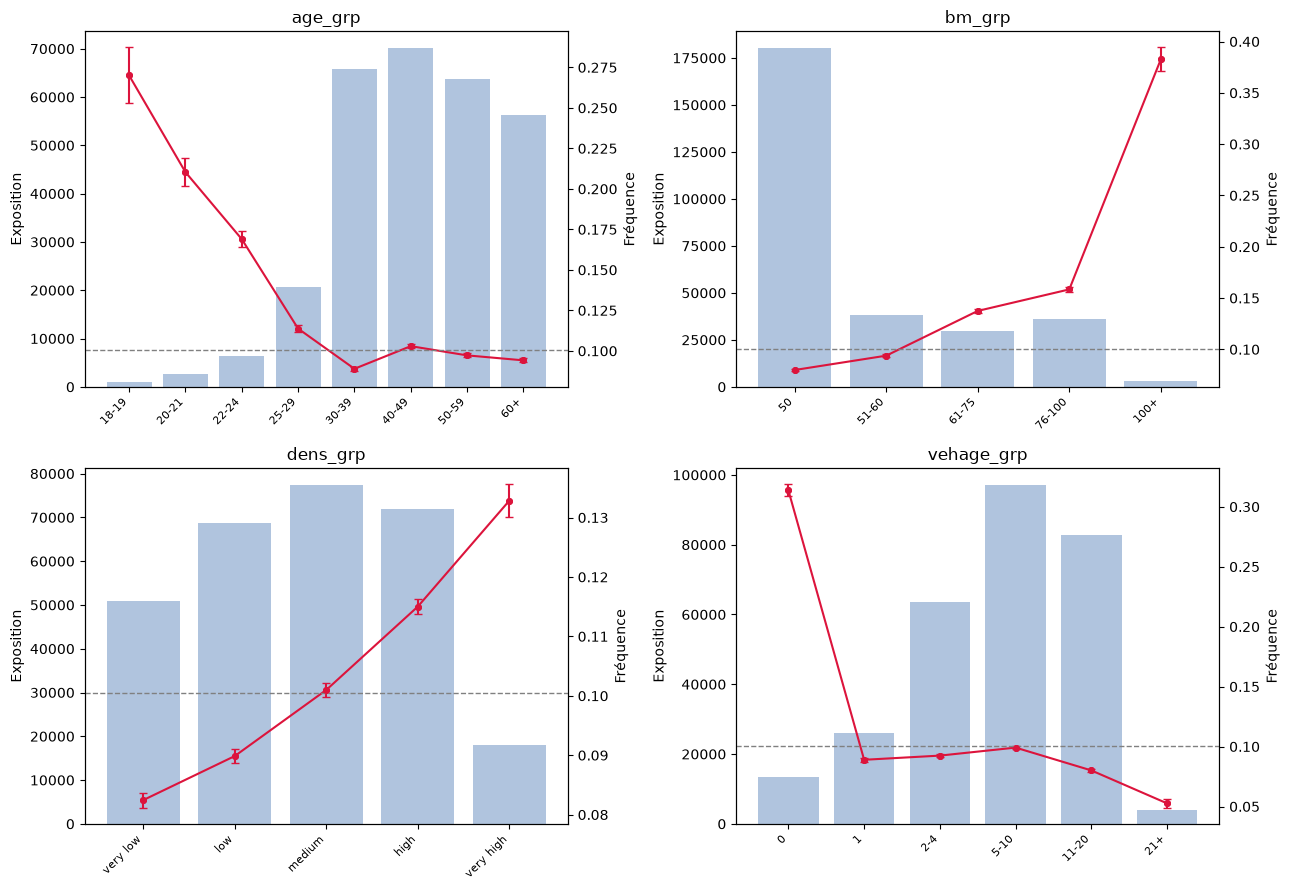

In [23]:
train_prep = preparer(train, decoupage="grossier")
test_prep  = preparer(test, decoupage="grossier")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]):
    plot_freq_par_groupe(train_prep, col, ax=ax, errorbar=True)
plt.tight_layout()


Pour les variables de catégorie, nous regroupons celles qui ont une exposition trop faible ( < 5000 ) car elles présenteraient une erreur relative trop importante sur la fréquence (pour 800 années-police -> environ 80 sinitres et une erreur relative de 11%).

In [24]:
modalites = {}

ETIQUETTE_AUTRE = {"VehPower": "12+", "Region": "Autres", "VehBrand": "Autres"}

for col in ["Region", "VehBrand", "VehPower"]:
    modalites[col] = modalites_frequentes(train_prep, col)
    train_prep = regrouper(train_prep, col, modalites[col], autre=ETIQUETTE_AUTRE[col])
    test_prep  = regrouper(test_prep,  col, modalites[col], autre=ETIQUETTE_AUTRE[col])


Nous allons regarder si certaines partie du découpages des variables `age_grp`, `bm_grp`, `dens_grp` et `vehage_grp` peuvent être fusionnées si elles ont un faible écart de fréquence et de petites erreurs relatives.

La statistique derrière cette fonction : l'écart type relatif du comptage vaut 1/√N (N = nombre de sinistres). Pour l'écart type de la fréquence, on divise par l'exposition qui est considérée comme une valeur connue et on obtient σ(f) = √N / exposition = f / √N.
Pour l'écart entre deux tranches, la variance d'une différence de deux variables aléatoires indépendantes est la somme des variances. Ainsi, le rapport |f₁ − f₂| / σ_écart compte l'écart en nombre d'écarts types ce qui permet de savoir réellement si l'écart observé est important.

In [25]:

for col in ["age_grp", "bm_grp", "dens_grp", "vehage_grp"]:
    print(f"\n === {col} === \n")
    print(comparer_tranches(train_prep, col))


 === age_grp === 

           paire     ecart  sigma_ecart   rapport
0  18-19 / 20-21  0.059678     0.019400  3.076198
1  20-21 / 22-24  0.041363     0.010237  4.040661
2  22-24 / 25-29  0.055220     0.005619  9.827525
3  25-29 / 30-39  0.024822     0.002620  9.473779
4  30-39 / 40-49  0.013979     0.001679  8.327129
5  40-49 / 50-59  0.005692     0.001730  3.291147
6    50-59 / 60+  0.003066     0.001788  1.714732

 === bm_grp === 

            paire     ecart  sigma_ecart    rapport
0      50 / 51-60  0.013968     0.001700   8.215515
1   51-60 / 61-75  0.043610     0.002664  16.369814
2  61-75 / 76-100  0.020974     0.003011   6.965382
3   76-100 / 100+  0.224172     0.011762  19.058303

 === dens_grp === 

              paire     ecart  sigma_ecart   rapport
0    very low / low  0.007413     0.001711  4.332397
1      low / medium  0.011127     0.001616  6.883772
2     medium / high  0.014026     0.001704  8.229313
3  high / very high  0.017828     0.003003  5.936061

 === vehage_gr

Pour `age_grp`, les fréquences de `60-69` (0.0934) et `70+` (0.0952) ne diffèrent que de 0.0012 pour un rapport de différence par rapport à l'écart-type de 0.68 . La distinction des deux catégorie n'est pas justifiée par les données observée, on peut donc les fusionner en `60+`.



Deux autres paires restent en zone grise et seront testé par AIC : 
- `age_grp` : `50-59` et `60+` (rapport 1.9)  
- `vehage_grp` : `1` et `2-4` (rapport 1.6)

In [26]:
X_train = train_prep
print(X_train.shape)
print(X_train.columns.tolist())

(542410, 17)
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region', 'age_grp', 'bm_grp', 'log_Density', 'dens_grp', 'vehage_grp']


In [27]:
y_train = train_prep["ClaimNb"]
offset_train = np.log(train_prep["Exposure"])

freq_formula = ("ClaimNb ~ C(age_grp, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))")


glm_freq = smf.glm(freq_formula, data=X_train, family=sm.families.Poisson(), offset=offset_train).fit()

print(glm_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:                            GLM   Df Residuals:                   542357
Model Family:                 Poisson   Df Model:                           52
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.1269e+05
Date:                Sat, 19 Sep 2026   Deviance:                   1.6993e+05
Time:                        22:21:27   Pearson chi2:                 1.25e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01705
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [28]:
mu = glm_freq.predict(X_train, offset=offset_train)
print("Somme des prédictions : ", mu.sum().round(1))
print("Somme des sinistres observés : ", y_train.sum())




Somme des prédictions :  28831.0
Somme des sinistres observés :  28831


### Spécification

Poisson à lien logarithmique, exposition en offset :

`log(E[ClaimNb]) = log(Exposure) + β′x`

L'offset entre avec un coefficient contraint à 1, de sorte que `exp(β′x)` s'interprète directement comme la fréquence annualisée.

53 paramètres estimés sur 542 410 polices.

Convergence de l'IRLS en 7 itérations.
Somme des prédictions égale à la somme des sinistres observés (propriété du lien canonique avec constante).
Aucune erreur standard aberrante : pas de colinéarité résiduelle après regroupement des modalités rares.

In [29]:
res = pd.DataFrame({"coef": glm_freq.params,"facteur": np.exp(glm_freq.params),"std_err": glm_freq.bse, "z": glm_freq.tvalues,}).round(4)
print(res)

                                                 coef  facteur  std_err  \
Intercept                                     -2.5432   0.0786   0.0327   
C(age_grp, Treatment('30-39'))[T.18-19]        0.7591   2.1364   0.0664   
C(age_grp, Treatment('30-39'))[T.20-21]        0.4121   1.5100   0.0460   
C(age_grp, Treatment('30-39'))[T.22-24]        0.1551   1.1677   0.0347   
C(age_grp, Treatment('30-39'))[T.25-29]       -0.0848   0.9187   0.0251   
C(age_grp, Treatment('30-39'))[T.40-49]        0.3537   1.4244   0.0183   
C(age_grp, Treatment('30-39'))[T.50-59]        0.3385   1.4029   0.0193   
C(age_grp, Treatment('30-39'))[T.60+]          0.3346   1.3973   0.0204   
C(bm_grp, Treatment('50'))[T.51-60]            0.2917   1.3388   0.0195   
C(bm_grp, Treatment('50'))[T.61-75]            0.6935   2.0007   0.0191   
C(bm_grp, Treatment('50'))[T.76-100]           0.8237   2.2788   0.0192   
C(bm_grp, Treatment('50'))[T.100+]             1.7050   5.5011   0.0337   
C(dens_grp, Treatment('me

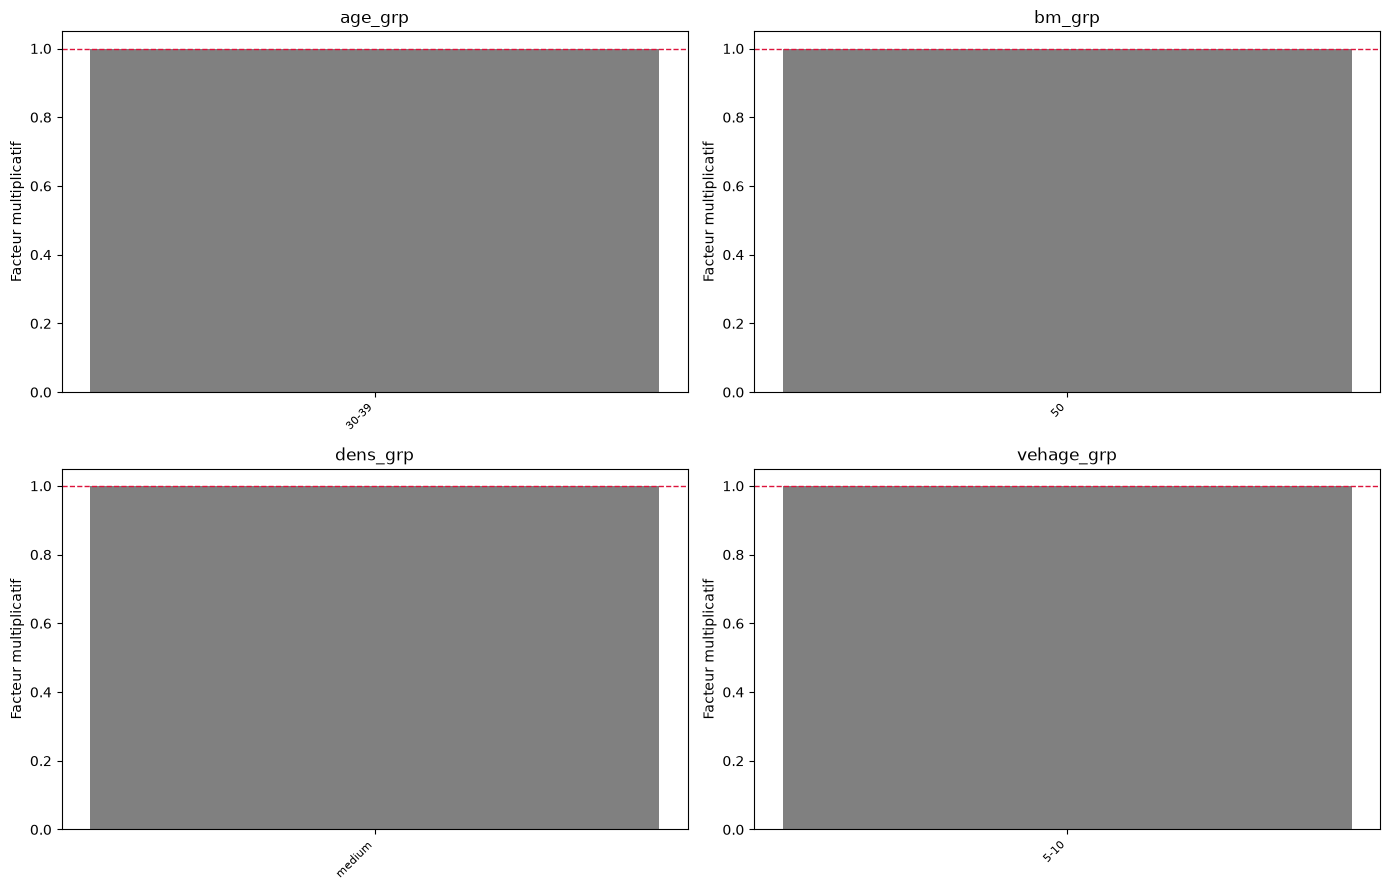

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_facteurs(glm_freq, "age_grp", ref="30-39",ax=axes.flat[0])
plot_facteurs(glm_freq, "bm_grp", ref="50",ax=axes.flat[1])
plot_facteurs(glm_freq, "dens_grp", ref="medium",ax=axes.flat[2])
plot_facteurs(glm_freq, "vehage_grp", ref="5-10",ax=axes.flat[3])

plt.tight_layout()

### Grille tarifaire estimée

Profil de référence : conducteur de 30-39 ans, bonus 50, densité moyenne, véhicule essence de 5-10 ans, puissance 6, marque B12, région R24. Fréquence prédite : 0,0786.

#### L'effet de l'âge est grandement modifié par le contrôle.
| ranche | Fréquence brute | Effet marginal |	Effet GLM |
|---|---|---|---|
|18-19|0,2700|×3,04|×2,14|
|20-21|	0,2104|	×2,37|	×1,51|
|22-24|0,1690|	×1,90|×1,17|
|25-29|	 0,1138|  ×1,28|	×0,92|
|30-39|	0,0889|	×1,00|	×1,00|
|40-49|0,1029|×1,16|	×1,42|
|50-59|0,0972|	×1,09|	×1,40|
|60+|	0,0940|	 ×1,06|	×1,40|

Observations : 

- Les jeunes sont attenués d'un tier. Le facteur 3.04 observé chez les `18-19` passe à 2.14 une fois les autres variables contrôlées.

- La tranche 25-29 change de signe. Supérieur de 28 % en brut, elle est inférieur de 8 % à profil comparable.

- Les 40+ sont amplifiés, de ×1,10 environ à ×1,40.

#### Autres variables :

- `Bonus-malus` : la variable dominante : ×1,34 (51-60), ×2,00 (61-75), ×2,28 (76-100), ×5,50 (100+). Strictement monotone, tous les coefficients au-delà de 14 σ montrent que cette variable est très significative dans la tarification.

- `Âge du véhicule` : le véhicule de moins d'un an ressort à ×3,12, contre ×3,17 en marginal : l'effet est pratiquement inchangé par le contrôle, donc indépendante aux autres variables. L'interprétation reste ouverte : déclaration systématique des dommages légers sur un véhicule neuf, relation contractuelle récente... Les données ne permettent pas de trancher.

- `Densité` : fortement atténuée : l'amplitude passe de 1 à 1,61 en marginal à 1 à 1,22 après contrôle.

- `Puissance, marque, région` — effets faibles et, pour la puissance, non monotones. Pl




|Question|	Raisonnement |
|---|---|
|Fusionner 40-49, 50-59 et 60+ en 40+|	Les coefficients des trois tranches au-delà de 40 ans valent 0,354, 0,339 et 0,335, pour des erreurs standards de l'ordre de 0,019. L'écart entre les extrêmes est de 0,019, soit 0,7 fois son propre écart-type : les trois tranches ne sont pas distinguables une fois les autres variables contrôlées.|
|Fusionner high et very high|	Écart de 0,012 pour un écart-type combiné de 0,032 soit 0,4 fois l'écart type.|
|Conserver VehPower ?|	Non monotone : ×0,76 en puissance 8, ×1,07 en 9, soit un saut de 41 % entre deux modalités contiguës — indéfendable dans une grille. Trois modalités non significatives. À tester en bloc par déviance.|
|Interaction age_grp × dens_grp|	Question ouverte depuis la phase 0 (ratios non constants de zone en zone).|



In [31]:
mask = (
    (train_prep["age_grp"] == "30-39") & (train_prep["bm_grp"] == "50")
    & (train_prep["dens_grp"] == "medium") & (train_prep["vehage_grp"] == "5-10")
    & (train_prep["VehGas"] == "Regular") & (train_prep["VehPower"] == "6")
    & (train_prep["VehBrand"] == "B12") & (train_prep["Region"] == "R24")
)
sous = train_prep[mask]
print(sous)
#print(len(sous), sous["Exposure"].sum(), sous["ClaimNb"].sum() / sous["Exposure"].sum())

Empty DataFrame
Columns: [IDpol, ClaimNb, Exposure, Area, VehPower, VehAge, DrivAge, BonusMalus, VehBrand, VehGas, Density, Region, age_grp, bm_grp, log_Density, dens_grp, vehage_grp]
Index: []


Je voulais vérifier que la fréquence annualisé d'un assuré présentant les caractéristiques de références était la même que celle prédite par le modèle mais aucun assuré ne les cummule toutes.

Cela n'invalide en rien les résultats, en effet certaines des caractéristiques de référence étaient en proportion faible dans le portefeuille, toutes cumulées, cela devient très rare.

Nous allons donc relâcher les contraintes faibles et garder les plus dominantes.

In [32]:
mask = (
    (train_prep["age_grp"] == "30-39")
    & (train_prep["bm_grp"] == "50")
    & (train_prep["vehage_grp"] == "5-10")
)
sous = train_prep[mask]
#print(sous)

print(len(sous), sous["Exposure"].sum().round(0), (sous["ClaimNb"].sum() / sous["Exposure"].sum()).round(4))

print(mu[mask].sum() / sous["Exposure"].sum())

14883 9470.0 0.0518
0.05793332001966062


In [33]:
print(f"Pearson χ²/df {(glm_freq.pearson_chi2 / glm_freq.df_resid).round(3)} (1.0 = perfect for Poisson)")

Pearson χ²/df 2.308 (1.0 = perfect for Poisson)


#### Réserve sur la dispersion

La loi de Poisson impose `Var(N) = E[N]`. Or cette contrainte est presque toujours brisée en assurance car les polices d'un même profil en apparance sont différentes sur des modalités non observées : kilométrage moyen, usage ...

Le rapport de Pearson `χ²/df = 2,30` évoque une surdispersion d'un facteur 2.30. Si la variance est 2.3 fois plus grande, alors les erreurs standards sont sous-estimées et les vrais sont `√2,3 ≈ 1,5` plus grandes. Les p-valeurs affichées sont donc trop optimistes, en particulier pour les modalités très significatives.

Une réserve est quand même émise sur la statistique de Pearson car elle divise par l'exposition qui peut être très petite. Ce chiffre peut donc être surestimé par quelques observations extrêmes.

La loi de Poisson suppose que la variance est égale à la moyenne. Les données suggèrent qu'elle est 2.3 fois plus grande, nous allons donc essayer avec une autre loi : la Negative-Binomial (Var = μ + αμ², avec α un paramètre de dispersion) qui estime directement l'excès de variance.

In [34]:
#on fait partir l'entrainement avec les parametre de la poisson pour que cela converge très vite vers la solution et gagner en temps de calcul.
start = np.append(glm_freq.params.to_numpy(), np.log(1.5))

glm_nb = smf.negativebinomial(freq_formula, data=X_train, offset=offset_train,loglike_method="nb2").fit(start_params=start , maxiter=200, disp=1)
print(glm_nb.summary())

Optimization terminated successfully.
         Current function value: 0.207339
         Iterations: 65
         Function evaluations: 68
         Gradient evaluations: 68
                     NegativeBinomial Regression Results                      
Dep. Variable:                ClaimNb   No. Observations:               542410
Model:               NegativeBinomial   Df Residuals:                   542357
Method:                           MLE   Df Model:                           52
Date:                Sat, 19 Sep 2026   Pseudo R-squ.:                 0.03813
Time:                        22:21:43   Log-Likelihood:            -1.1246e+05
converged:                       True   LL-Null:                   -1.1692e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------

In [35]:
mu = glm_nb.predict(X_train, offset=offset_train)
print("Somme des prédictions : ", mu.sum().round(1))
print("Somme des sinistres observés : ", y_train.sum())
print("Ecart en % : ", (mu.sum().round(4) - y_train.sum()) / y_train.sum() * 100)

# Calcule du facteur de recalage.

facteur = y_train.sum() / mu.sum()
mu_nb = mu * facteur
print("écart après recalage :", round(100 * (mu_nb.sum() - y_train.sum()) / y_train.sum(), 6))



Somme des prédictions :  29205.5
Somme des sinistres observés :  28831
Ecart en % :  1.2991200443966522
écart après recalage : 0.0


La binomiale négative surestime de 1,3 % (29 205 prédits), l'égalité des totaux n'étant pas garantie hors du cadre canonique. Un facteur de recalage multiplicatif de 0,9872, estimé sur le train, rétablit la calibration sans modifier les rapports entre segments.

In [36]:
comparaison = pd.DataFrame({
    'Poisson': np.exp(glm_freq.params),
    'Neg-Binomial': np.exp(glm_nb.params)
})

comparaison["Difference"] = comparaison["Poisson"] - comparaison["Neg-Binomial"]
comparaison['Diff_pct'] = (comparaison['Difference'] / comparaison['Poisson'] * 100)

print(comparaison.iloc[1:][['Poisson', 'Neg-Binomial', 'Diff_pct']].round(4).to_string())

                                               Poisson  Neg-Binomial  Diff_pct
C(Region, Treatment('R24'))[T.R11]              0.9068        0.9094   -0.2960
C(Region, Treatment('R24'))[T.R25]              0.9447        0.9442    0.0558
C(Region, Treatment('R24'))[T.R31]              0.8769        0.8784   -0.1698
C(Region, Treatment('R24'))[T.R41]              0.7796        0.7756    0.5157
C(Region, Treatment('R24'))[T.R52]              0.9409        0.9383    0.2776
C(Region, Treatment('R24'))[T.R53]              1.0319        1.0304    0.1466
C(Region, Treatment('R24'))[T.R54]              0.8902        0.8885    0.1867
C(Region, Treatment('R24'))[T.R72]              0.8476        0.8430    0.5496
C(Region, Treatment('R24'))[T.R73]              0.8267        0.8252    0.1777
C(Region, Treatment('R24'))[T.R82]              1.0088        1.0097   -0.0895
C(Region, Treatment('R24'))[T.R91]              0.8749        0.8752   -0.0325
C(Region, Treatment('R24'))[T.R93]              0.90

Écarts très faibles dans l'ensemble, sauf pour `vehage_grp_0` avec 5% puis `bm_grp_100+`, `age_grp_18-19`, `age_grp_20-21` et `bm_grp_76-100` au dessus de 1%.


`AIC = −2ℓ + 2k` 


`BIC = −2ℓ + log(n)·k ,  n = 542 410`


In [37]:
comp = pd.DataFrame({
    "log-vraisemblance": [glm_freq.llf, glm_nb.llf],
    "AIC": [glm_freq.aic, glm_nb.aic],
    "BIC": [glm_freq.bic_llf, glm_nb.bic],
    "paramètres": [53, 54],
}, index=["Poisson", "Binomiale négative"])
print(comp.round(1))

                    log-vraisemblance       AIC       BIC  paramètres
Poisson                     -112690.4  225486.8  226080.6          53
Binomiale négative          -112462.9  225033.7  225638.7          54


La binomiale négative ajuste mieux la dispersion mais perd la calibration automatique ; la Poisson est moins bien ajustée mais exactement calibrée. Pour un modèle destiné à produire un tarif, cette dernière propriété est loin d'être secondaire.

Modèle retenu : la binomiale négative. Elle est meilleur sur la vraissemblance, améliore l'AIC de 453 points et le BIC dans les mêmes proportions, pour un seul paramètre supplémentaire.

La différence ne porte pas sur le tarif : 45 des 53 coefficients diffèrent de moins de 1 % de ceux de la Poisson, puisque la prime pure ne dépend que de l'espérance et que les deux lois ont la même. La différence est sur la significativié des variables : `VehPower_9` cesse d'être significative avec le modèle négative binomiale, et porte aussi sur l'estimation de la dispertion, qui servira au chargement de sécurité pour la prime chargée. Comme la Poisson impose `Var = E` alors qu'elle est en réalité plus grande, cela conduirait à sous estimer le capital requis.



 
Problème rencontré à documenter : lors du premier entrainement du modèle négative binomiale, je suis parti de l'initialisation par défaut, mais cela ne convergeait pas. Suite à des recherches (notamment sur le forum Stack OverFlow), j'ai vu que c'était un problème connu du GLM Negative Binomial qui utilise un méthode de Newton pour converger et que la fonction de moyenne exponentielle peut facilement entraîner des problèmes de dépassement de capacité ou des difficultés liées à des gradients et des matrices hessiennes de grande taille lorsque nous sommes encore loin de l'optimum. . Une solution consistait à mettre comme initialisation les résultats d'un autre modèle pour que le point de départ soit beaucoup plus proche de la solution et que cela converge rapidement.



#### Test de l'intéraction `DrivAge` et `Density` 

Rappel : la phase 0 avait relevé que les ratios de fréquence par tranche d'âge n'étaient pas constants d'une zone à l'autre, ce qui contredit l'hypothèse multiplicative du GLM. On teste formellement l'ajout des 28 termes croisés `age_grp × dens_grp` au modèle de base.

Les coefficients des deux lois diffèrent de moins de 1 % sur 45 des 53 modalités. Les deux spécifient la moyenne de façon identique et ne diffèrent que par la variance, qui n'intervient pas dans le choix des variables explicatives. Les tests de structure sont donc conduits en Poisson, dont l'ajustement est plus rapide et plus stable, et le modèle finalement retenu est réajusté en binomiale négative.

La surdispersion conduit la Poisson à surestimer les gains de vraisemblance ; les valeurs de LR et les écarts d'AIC rapportés dans cette section sont donc optimistes en niveau.

In [38]:
m_base = smf.glm(freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

# le caractere * à la place du + dans la formule permet d'ajouter le fait qu'on suggère une intéraction entre les deux.

interaction_freq_formula = ("ClaimNb ~ C(age_grp, Treatment('30-39')) * C(dens_grp, Treatment('medium'))"
         " + C(bm_grp, Treatment('50'))"
         " + C(vehage_grp, Treatment('5-10'))"
         " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
         " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))")

m_inter = smf.glm(interaction_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

In [39]:
# LR = 2 × (ℓ_avec_interaction − ℓ_base) = 106,8

LR = m_base.deviance - m_inter.deviance
ddl = m_inter.df_model - m_base.df_model


print(f"LR = {LR.round(1)} sur {ddl} ddl, p = {stats.chi2.sf(LR, ddl).round(4)}")
print(f"AIC : {m_base.aic.round(0)} -> {m_inter.aic.round(0)}")
print(f"BIC : {m_base.bic_llf.round(0)} -> {m_inter.bic_llf.round(0)}")

LR = 106.8 sur 28 ddl, p = 0.0
AIC : 225487.0 -> 225436.0
BIC : 226081.0 -> 226344.0


Les trois critères divergent sur la décision finale parce qu'ils pénalisent différemment les 28 paramètres ajoutés : le test du rapport de vraisemblance exige un gain de 41 (quantile à 95 % d'une loi du khi-deux à 28 degrés de liberté (cf cours de modèles statistiques test de Wilks)), l'AIC de 56, le BIC de log(542 410) × 28 ≈ 370. Le gain observé est de 106,8.

(Les seuils sur l'AIC et le BIC découlent de leur formule de définition, comme k = nb_de_parametre_ajouté augmente, il faut que −2·ℓ diminue et donc que ℓ augmente d'au moins autant pour avoir un gain.)

l'interaction existe, mais elle est trop diffuse pour justifier 28 paramètres supplémentaires. Le signal réel se concentre sur quelques catégories, les autres ne contribuent que du bruit tout en coûtant chacune un degré de liberté.

In [40]:
#l'affichage etait tronqué "..." sur la partie des catégories la plus importante.
pd.set_option("display.max_colwidth", None)

inter_coefs = m_inter.params.filter(like=":")
inter_bse = m_inter.bse.filter(like=":")
t = pd.DataFrame({"coef": inter_coefs, "z": inter_coefs / inter_bse})
print(t.reindex(t["z"].abs().sort_values(ascending=False).index).round(3).head(10))

                                                                                        coef  \
C(age_grp, Treatment('30-39'))[T.50-59]:C(dens_grp, Treatment('medium'))[T.high]      -0.218   
C(age_grp, Treatment('30-39'))[T.40-49]:C(dens_grp, Treatment('medium'))[T.very high] -0.301   
C(age_grp, Treatment('30-39'))[T.40-49]:C(dens_grp, Treatment('medium'))[T.high]      -0.158   
C(age_grp, Treatment('30-39'))[T.50-59]:C(dens_grp, Treatment('medium'))[T.very high] -0.213   
C(age_grp, Treatment('30-39'))[T.60+]:C(dens_grp, Treatment('medium'))[T.very low]     0.144   
C(age_grp, Treatment('30-39'))[T.60+]:C(dens_grp, Treatment('medium'))[T.high]        -0.117   
C(age_grp, Treatment('30-39'))[T.18-19]:C(dens_grp, Treatment('medium'))[T.low]        0.304   
C(age_grp, Treatment('30-39'))[T.20-21]:C(dens_grp, Treatment('medium'))[T.very low]   0.225   
C(age_grp, Treatment('30-39'))[T.22-24]:C(dens_grp, Treatment('medium'))[T.very low]  -0.180   
C(age_grp, Treatment('30-39'))[T.20-21]:

L'intéraction se concentre principalement sur les tranches `40-49` (high : 3.4 σ et very high : 4.4 σ), `50-59` (high : 4.4 σ et very high : 3.0 σ) et sur `60+` (very low : 2.3 σ, high : 2.3 σ)

les six catégories significatives concernent tous les conducteurs de 40 ans et plus ; aucune tranche jeune ne dépasse 1,8 σ.

L'interaction complète étant rejetée par le BIC, on teste une version restreinte au seul bloc où le signal se concentre : âge ≥ 40 croisé avec densité élevée (high + very high), soit un paramètre au lieu de 28.

In [41]:
# Préparation des catégories 
# Indicateurs convertis en 0/1 plutôt qu'en booléen car sinon l'entrainement tournait à l'infini. (solution trouvé sur stack overflow, je n'ai pas tout compris à l'explication ... (le booléen recréait trois catégories lors du matrice design, trois vecteur quasiment linéairement dépendants ce qui rendait la matrice presque ininversible et donc l'algo galérait... un truc comme ça))
train_prep["age40p"] = train_prep["age_grp"].astype(str).isin(["40-49", "50-59", "60+"]).astype(int)
train_prep["dense"]  = train_prep["dens_grp"].astype(str).isin(["high", "very high"]).astype(int)

test_prep["age40p"] = test_prep["age_grp"].astype(str).isin(["40-49", "50-59", "60+"]).astype(int)
test_prep["dense"]  = test_prep["dens_grp"].astype(str).isin(["high", "very high"]).astype(int)

# Vérification des effectifs 
print(pd.crosstab(train_prep["age40p"], train_prep["dense"], values=train_prep["Exposure"], aggfunc="sum").round(0))

restreint_formula = freq_formula + " + age40p:dense"


dense          0        1
age40p                   
0        64268.0  32328.0
1       132702.0  57479.0


In [50]:
glm_restreint = smf.glm(restreint_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()



comparer_modeles_glm(m_base, glm_restreint, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 1) ===
Action détectée : AJOUT
Statistique LR calculée : 68.49 (p-value : 1.2780e-16)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 3.84 ➔ ("Rejet de H0 : L'ajout est significatif (Modèle complexe retenu)",)
2. Critère AIC        : Seuil = 2.00 ➔ ("Rejet de H0 : L'ajout est significatif (Modèle complexe retenu)",)
3. Critère BIC        : Seuil = 13.20 ➔ ("Rejet de H0 : L'ajout est significatif (Modèle complexe retenu)",)


{'lr_stat': 68.48571004491532,
 'p_value': 1.2780035531122132e-16,
 'ddl': np.int64(1),
 'action': 'AJOUT',
 'valide_test': np.True_,
 'valide_aic': np.True_,
 'valide_bic': np.True_}

LR = 68,5 sur 1 degré de liberté, contre des seuils de 3,84 (test), 2 (AIC) et 13,2 (BIC). Les trois critères retiennent l'interaction. L'AIC passe de 225 487 à 225 420 et le BIC de 226 081 à 226 025.

Ce modèle domine également la version à 28 paramètres sur les deux critères d'information (AIC 225 420 contre 225 436 ; BIC 226 025 contre 226 344) : un seul paramètre récupère 64 % du gain de vraisemblance, les 27 autres coûtant plus qu'ils n'apportent. Le diagnostic de six termes réels noyés dans vingt-deux termes de bruit est confirmé.

Le coefficient vaut −0,211, soit un facteur de 0,81. Pour un conducteur de 40 ans et plus, le facteur de la zone high passe de 1,069 à 0,866 : le surcoût des zones denses ne s'annule pas seulement au-delà de 40 ans, il s'inverse.

#### Test fusion `DrivAge` `50-59` et `60+`

Le modèle de référence est maintenant celui avec l'intéraction -> glm_restreint.

Rappel : Le modèle donnait des coefficients de 0,339 et 0,335 pour des écarts-types de 0,019 : indistinguables.

In [51]:
FUSION_AGE = {"50-59": "50+", "60+": "50+"}

train_prep["age_grp2"] = train_prep["age_grp"].astype(str).replace(FUSION_AGE)
test_prep["age_grp2"] = test_prep["age_grp"].astype(str).replace(FUSION_AGE)

# On integres l'interaction précédemment adoptée.

interaction_2_freq_formula = ("ClaimNb ~ C(age_grp2, Treatment('30-39')) + C(bm_grp, Treatment('50'))"
        " + C(dens_grp, Treatment('medium')) + C(vehage_grp, Treatment('5-10'))"
        " + C(VehGas, Treatment('Regular')) + C(VehPower, Treatment('6'))"
        " + C(VehBrand, Treatment('B12')) + C(Region, Treatment('R24'))" 
         " + age40p:dense")

glm_interaction_2 = smf.glm(interaction_2_freq_formula, data=train_prep,family=sm.families.Poisson(),offset=offset_train).fit()

comparer_modeles_glm(glm_restreint, glm_interaction_2, alpha=0.05)

=== COMPARAISON DE MODÈLES GLM (n = 542410, |Δddl| = 1) ===
Action détectée : RETRAIT OU FUSION
Statistique LR calculée : 0.10 (p-value : 7.5223e-01)
-----------------------------------------------------------------
1. Test LR (α=5.0%)   : Seuil = 3.84 ➔ ✅ Non-rejet de H0 : La simplification est acceptable (Modèle simplifié conservé par parcimonie)
2. Critère AIC        : Seuil = 2.00 ➔ ✅ Non-rejet de H0 : La simplification est acceptable (Modèle simplifié conservé par parcimonie)
3. Critère BIC        : Seuil = 13.20 ➔ ✅ Non-rejet de H0 : La simplification est acceptable (Modèle simplifié conservé par parcimonie)


{'lr_stat': 0.09966408662148751,
 'p_value': 0.7522331161698271,
 'ddl': np.int64(1),
 'action': 'RETRAIT OU FUSION',
 'valide_test': np.False_,
 'valide_aic': np.False_,
 'valide_bic': np.False_}

La fusion en 50+ est adoptée est donc adoptée.